# Part 2: Action Chunking with Conditional Flow Matching

Same task, demonstration split, normalizer (loaded from Part 1, not refit), chunk length $K=8$, architecture
width/depth, optimizer and step budget as Part 1. Only the way a chunk is represented and generated changes.

## 1. Setup

In [1]:
import json, time, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import Image as ShowImage, display

from pusht_ac.data import Normalizer, PushtChunkDataset, download_pusht, load_pusht_zarr
from pusht_ac.model import build_policy, save_policy, load_policy, FlowMatchingPolicy
from pusht_ac.train import train_policy
from pusht_ac.evaluation import VAL_SEEDS, TEST_SEEDS, evaluate, summarize, rollout, save_gif
from pusht_ac.stats import paired_summary
from pusht_ac import viz
from pusht_ac.viz import PAL

torch.set_num_threads(4)
RES, CKPT, RES1 = Path('results_part2'), Path('checkpoints'), Path('results_part1')
RES.mkdir(exist_ok=True)
RETRAIN = not (CKPT / 'flow_policy.pt').exists()
CFG1 = json.load(open(RES1 / 'config.json'))
CFG = dict(CFG1, flow_steps_N=10, flow_time_input='raw scalar tau in [0,1] concatenated', train_seed=0,
           test_policy_seed='reset_seed + offset (offset 0 is the primary run; 10000 and 20000 are repeats)')
json.dump(CFG, open(RES / 'config.json', 'w'), indent=2)

states, actions, episode_ends = load_pusht_zarr(download_pusht(Path('data')))
split = json.load(open(CKPT / 'split.json'))
normalizer = Normalizer.load(CKPT / 'normalizer.json')   # frozen statistics from Part 1
K = CFG['chunk_size']
train_ds = PushtChunkDataset(states, actions, episode_ends, K, normalizer, split['train_episodes'])
val_ds = PushtChunkDataset(states, actions, episode_ends, K, normalizer, split['val_episodes'])
print(len(train_ds), len(val_ds))

19529 4679


## 2. Task 1: Construct conditional flow-matching examples

$A_\tau=(1-\tau)\epsilon+\tau A$, $u=A-\epsilon$, with $\tau=0$ noise and $\tau=1$ data. The velocity network sees
$[o, A_\tau, \tau]$: 5 + 16 + 1 = 22 inputs and 16 outputs.

In [2]:
torch.manual_seed(0)
o, A = train_ds.obs[:4], train_ds.chunks[:4]
eps = torch.randn_like(A)
A0, u = FlowMatchingPolicy.interpolate(A, eps, torch.zeros(4))
A1, _ = FlowMatchingPolicy.interpolate(A, eps, torch.ones(4))
Ah, _ = FlowMatchingPolicy.interpolate(A, eps, torch.full((4,), 0.25))
probe = build_policy('flow', chunk_size=K, hidden_dims=tuple(CFG['hidden_dims']))
x_in = torch.cat([o, Ah.flatten(1), torch.full((4, 1), 0.25)], 1)
checks = {
    'A_tau at tau=0 equals eps': torch.allclose(A0, eps),
    'A_tau at tau=1 equals A': torch.allclose(A1, A),
    'A_tau at tau=0.25 equals 0.75 eps + 0.25 A': torch.allclose(Ah, 0.75 * eps + 0.25 * A),
    'target u = A - eps has shape [B, K, 2]': tuple(u.shape) == (4, K, 2),
    'velocity input width = 5 + 2K + 1 = 22': x_in.shape[1] == 22 == probe.net[0].in_features,
    'velocity output shape [B, K, 2]': tuple(probe.velocity(o, Ah, torch.full((4,), 0.25)).shape) == (4, K, 2),
    'moving along u for the remaining time reaches A': torch.allclose(Ah + 0.75 * u, A, atol=1e-6),
}
for k_, v in checks.items():
    print(f'{"PASS" if v else "FAIL"}  {k_}')
assert all(checks.values())
print('\nsample_actions(state, num_steps, generator) only takes the observation; the clean chunk is never an input at sampling time.')
print('example tau=0.25 numbers, first action of chunk 0:  eps', eps[0, 0].numpy().round(3), ' A', A[0, 0].numpy().round(3),
      ' A_tau', Ah[0, 0].numpy().round(3), ' u', u[0, 0].numpy().round(3))

PASS  A_tau at tau=0 equals eps
PASS  A_tau at tau=1 equals A
PASS  A_tau at tau=0.25 equals 0.75 eps + 0.25 A
PASS  target u = A - eps has shape [B, K, 2]
PASS  velocity input width = 5 + 2K + 1 = 22
PASS  velocity output shape [B, K, 2]
PASS  moving along u for the remaining time reaches A

sample_actions(state, num_steps, generator) only takes the observation; the clean chunk is never an input at sampling time.
example tau=0.25 numbers, first action of chunk 0:  eps [-1.126 -1.152]  A [-1.153 -0.211]  A_tau [-1.133 -0.917]  u [-0.027  0.942]


## 3. Task 2: Train the conditional velocity model

Per-example loss $\ell_{FM}=\frac{1}{2K}\|v_\theta(o,A_\tau,\tau)-(A-\epsilon)\|_F^2$, minibatch mean; fresh $\epsilon$
and $\tau\sim U[0,1]$ every step. Same MLP size (3 × 256, ReLU), Adam 3e-4, batch 128, 150k steps, and the same
validation-rollout checkpoint rule as Part 1 (validation rollouts use $N=10$ and policy seed = reset seed).
The differences are the 17 extra input values ($A_\tau$ and $\tau$; 4,352 more first-layer weights), a
noisier regression target, and the 10-step sampler at test time.

In [3]:
if RETRAIN:
    flow = build_policy('flow', chunk_size=K, hidden_dims=tuple(CFG['hidden_dims']))
    flow, log, evals, info, _ = train_policy(flow, train_ds, val_ds, normalizer, steps=CFG['steps'],
                                             batch_size=CFG['batch_size'], lr=CFG['lr'], eval_every=CFG['eval_every'],
                                             seed=CFG['train_seed'], num_steps=CFG['flow_steps_N'])
    save_policy(flow, CKPT / 'flow_policy.pt', **info, flow_steps_N=CFG['flow_steps_N'])
    log.to_csv(RES / 'flow_train_log.csv', index=False); evals.to_csv(RES / 'flow_val_rollouts.csv', index=False)
    json.dump(info, open(RES / 'flow_train_info.json', 'w'), indent=2)
sha = hashlib.sha256(open(CKPT / 'flow_policy.pt', 'rb').read()).hexdigest()
(RES / 'flow_checkpoint_sha256.txt').write_text(sha)
flow = load_policy(CKPT / 'flow_policy.pt')
log, evals = pd.read_csv(RES / 'flow_train_log.csv'), pd.read_csv(RES / 'flow_val_rollouts.csv')
info = json.load(open(RES / 'flow_train_info.json'))
info1 = json.load(open(RES1 / 'mse_train_info.json'))
print(f"parameters: {sum(p.numel() for p in flow.parameters()):,}   checkpoint sha256 {sha[:16]}…")
pd.DataFrame({'MSE (Part 1)': info1, 'Flow (Part 2)': info}).round(1)

step   5000  train 0.3181  val 0.3420  val-rollout score 0.237  success 0.00


step  10000  train 0.2823  val 0.3062  val-rollout score 0.300  success 0.00


step  15000  train 0.2609  val 0.2870  val-rollout score 0.434  success 0.02


step  20000  train 0.2476  val 0.2757  val-rollout score 0.480  success 0.00


step  25000  train 0.2373  val 0.2626  val-rollout score 0.602  success 0.02


step  30000  train 0.2253  val 0.2580  val-rollout score 0.595  success 0.10


... (22 outputs left out)

step 145000  train 0.1570  val 0.2572  val-rollout score 0.803  success 0.20


step 150000  train 0.1518  val 0.2594  val-rollout score 0.781  success 0.24


parameters: 141,584   checkpoint sha256 319c4e455c89da57…


,MSE (Part 1),Flow (Part 2)
best_step,115000.0,130000.0
train_time_s,271.7,193.5
val_rollout_time_s,136.1,131.9
wall_time_s,412.4,328.7


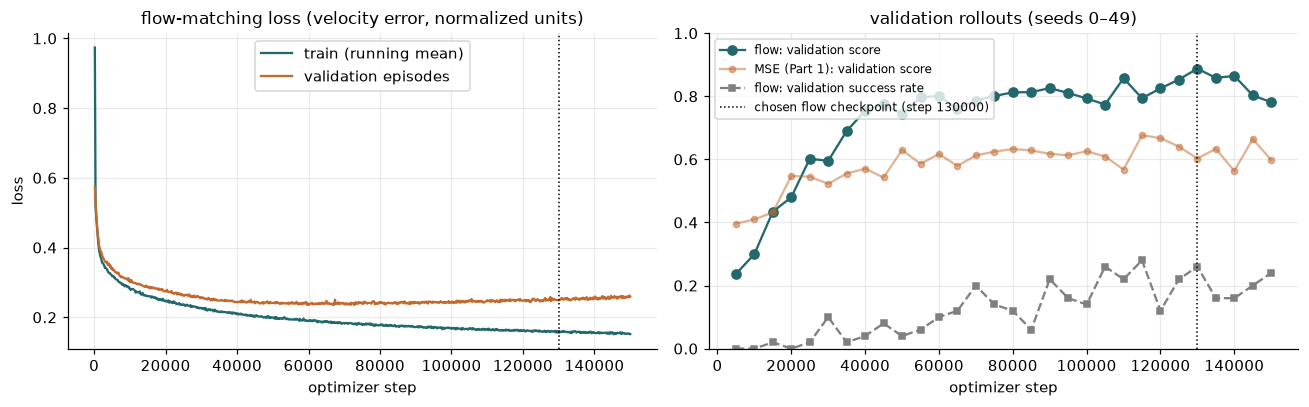

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
viz.plot_losses(axes[0], log, 'flow-matching loss (velocity error, normalized units)', 'loss')
axes[0].axvline(info['best_step'], color='k', ls=':', lw=1)
ev1 = pd.read_csv(RES1 / 'mse_val_rollouts.csv')
axes[1].plot(evals.step, evals.val_score, 'o-', color=PAL['flow'], label='flow: validation score')
axes[1].plot(ev1.step, ev1.val_score, 'o-', color=PAL['mse'], alpha=0.5, ms=4, label='MSE (Part 1): validation score')
axes[1].plot(evals.step, evals.val_success, 's--', color='gray', ms=4, label='flow: validation success rate')
axes[1].axvline(info['best_step'], color='k', ls=':', lw=1, label=f"chosen flow checkpoint (step {info['best_step']})")
axes[1].set_ylim(0, 1); axes[1].set_xlabel('optimizer step'); axes[1].legend(fontsize=8); axes[1].set_title('validation rollouts (seeds 0–49)')
plt.tight_layout(); plt.savefig(RES / 'flow_losses.png', bbox_inches='tight'); plt.show()

## 4. Task 3: Generate chunks and compare with Part 1

Euler sampler $Z_{n+1}=Z_n+\frac1N v_\theta(o,Z_n,n/N)$, $N=10$, fresh $Z_0\sim\mathcal N(0,I)$ at every query
(from a per-episode generator seeded with the policy seed). Those 10 network evaluations happen before any
physical action; then the 8 actions of $Z_N$ are denormalized, clipped and executed.

The primary run uses policy seed = reset seed. Two more passes with different policy seeds measure how much the
test score moves with sampling noise alone.

In [5]:
runs = {}
for off in (0, 10_000, 20_000):
    df, _ = evaluate(flow, normalizer, TEST_SEEDS, policy_seed_offset=off, num_steps=10)
    df.to_csv(RES / f'flow_test_episodes_offset{off}.csv', index=False)
    runs[off] = df
flow_df = runs[0]
mse_df = pd.read_csv(RES1 / 'mse_test_episodes.csv')

def row(df, name, train_info):
    s = summarize(df); nq = int(np.ceil(df.length / K).sum())
    return {'policy': name, 'score mean': s['score_mean'], 'score std': s['score_std'], 'success rate': s['success_rate'],
            'mean episode length': s['mean_length'], 'ms / policy query': 1000 * df.policy_time_s.sum() / nq,
            'rollout time, 100 episodes (s)': s['rollout_time_s'], 'training time (s)': train_info['train_time_s']}

comp = pd.DataFrame([row(mse_df, 'MSE (Part 1)', info1), row(flow_df, 'Flow, N=10 (Part 2)', info)]
                    + [row(runs[o_], f'Flow, policy-seed offset {o_}', info) for o_ in (10_000, 20_000)])
comp.to_csv(RES / 'mse_vs_flow_test.csv', index=False)
pair = paired_summary(mse_df.max_reward, flow_df.max_reward)
json.dump(pair, open(RES / 'flow_minus_mse_paired.json', 'w'), indent=2)
display(comp.round(3))
print('Flow - MSE on the same 100 test seeds:', {k_: round(v, 4) if isinstance(v, float) else v for k_, v in pair.items()})

,policy,score mean,score std,success rate,mean episode length,ms / policy query,"rollout time, 100 episodes (s)",training time (s)
0,MSE (Part 1),0.575,0.397,0.11,286.08,0.131,7.153,271.698
1,"Flow, N=10 (Part 2)",0.840,0.265,0.22,280.75,0.599,8.812,193.465
2,"Flow, policy-seed offset 10000",0.837,0.265,0.20,278.74,0.617,8.930,193.465
3,"Flow, policy-seed offset 20000",0.870,0.224,0.27,277.86,0.605,9.148,193.465


Flow - MSE on the same 100 test seeds: {'mean_diff': 0.2654, 'ci_low': 0.1738, 'ci_high': 0.3556, 'p_signflip': 0.0, 'wins': 70, 'ties': 5, 'losses': 25}


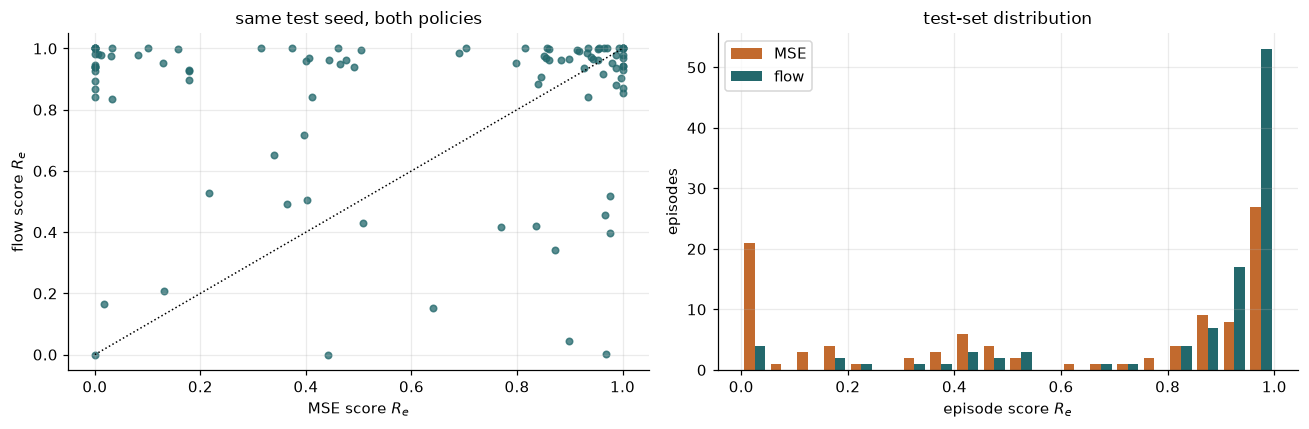

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(mse_df.max_reward, flow_df.max_reward, s=18, color=PAL['flow'], alpha=0.75)
axes[0].plot([0, 1], [0, 1], 'k:', lw=1)
axes[0].set_xlabel('MSE score $R_e$'); axes[0].set_ylabel('flow score $R_e$'); axes[0].set_title('same test seed, both policies')
bins = np.linspace(0, 1, 21)
axes[1].hist([mse_df.max_reward, flow_df.max_reward], bins=bins, color=[PAL['mse'], PAL['flow']], label=['MSE', 'flow'])
axes[1].set_xlabel('episode score $R_e$'); axes[1].set_ylabel('episodes'); axes[1].legend(); axes[1].set_title('test-set distribution')
plt.tight_layout(); plt.savefig(RES / 'mse_vs_flow.png', bbox_inches='tight'); plt.show()

### Number of integration steps N (validation seeds only)
$N$ only changes sampling compute and accuracy of the ODE solve; $K=8$ actions are executed per query regardless.

In [7]:
nrows = []
for N in (1, 2, 4, 10, 20, 50):
    df, _ = evaluate(flow, normalizer, VAL_SEEDS, num_steps=N)
    nq = int(np.ceil(df.length / K).sum())
    nrows.append({'N': N, 'val score': df.max_reward.mean(), 'val success': df.success.mean(),
                  'ms / query': 1000 * df.policy_time_s.sum() / nq})
nsweep = pd.DataFrame(nrows); nsweep.to_csv(RES / 'flow_N_sweep_val.csv', index=False)
nsweep.round(3)

,N,val score,val success,ms / query
0,1,0.621,0.14,0.170
1,2,0.744,0.24,0.228
2,4,0.868,0.22,0.308
3,10,0.888,0.26,0.588
4,20,0.845,0.14,1.019
5,50,0.838,0.28,2.458


### Several sampled chunks from one observation
Left: the observation chosen in Part 1 (where nearby demonstrations disagree) with 30 flow samples, the MSE chunk
and the neighbouring expert chunks. Right: the Euler path of the last action of 6 samples, from noise ($n=0$) to
the executed chunk ($n=N$).

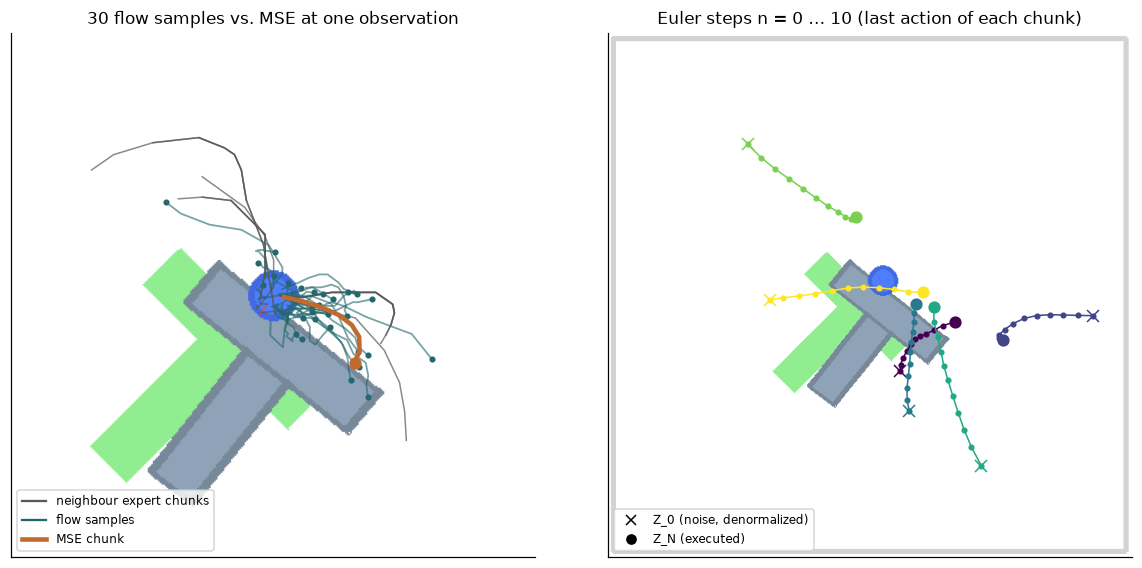

spread of sampled chunk end points (px, std x / y): [27.3 22.9]


In [8]:
mm = json.load(open(RES1 / 'multimodal_obs.json'))
qi, nn = mm['train_chunk_index'], mm['neighbors']
q_state = states[train_ds.indices[qi]]
raw_chunks = actions[train_ds.indices[:, None] + np.arange(K)]
mse = load_policy(CKPT / 'mse_policy.pt')
o_q = train_ds.obs[qi:qi + 1]
g = torch.Generator().manual_seed(7)
with torch.no_grad():
    samples = np.stack([normalizer.denormalize_action(flow.sample_actions(o_q, num_steps=10, generator=g)[0].numpy()) for _ in range(30)])
    pred_mse = normalizer.denormalize_action(mse(o_q)[0].numpy())
    # Euler path of a few samples
    z = torch.randn((6, K, 2), generator=torch.Generator().manual_seed(3)); path = [z.clone()]
    for n_ in range(10):
        z = z + flow.velocity(o_q.expand(6, -1), z, torch.full((6,), n_ / 10)) / 10; path.append(z.clone())
path = np.stack([normalizer.denormalize_action(p_.numpy()) for p_ in path])   # [N+1, 6, K, 2]

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
ax = axes[0]
viz.show_scene(ax, q_state, title='30 flow samples vs. MSE at one observation')
for j in nn:
    ax.plot(*raw_chunks[j].T, '-', color='0.35', lw=1, alpha=0.7)
for smp in samples:
    ax.plot(*smp.T, '-', color=PAL['flow'], lw=1.2, alpha=0.6); ax.plot(*smp[-1], 'o', color=PAL['flow'], ms=3)
ax.plot(*pred_mse.T, '-', color=PAL['mse'], lw=3); ax.plot(*pred_mse[-1], 'o', color=PAL['mse'], ms=7)
ax.plot([], [], color='0.35', label='neighbour expert chunks'); ax.plot([], [], color=PAL['flow'], label='flow samples')
ax.plot([], [], color=PAL['mse'], lw=3, label='MSE chunk'); ax.legend(loc='lower left', fontsize=8)
c = q_state[:2]; ax.set_xlim(c[0] - 154, c[0] + 154); ax.set_ylim(c[1] + 154, c[1] - 154)
ax = axes[1]
viz.show_scene(ax, q_state, title='Euler steps n = 0 … 10 (last action of each chunk)')
for j in range(6):
    ax.plot(path[:, j, -1, 0], path[:, j, -1, 1], '.-', color=plt.cm.viridis(j / 5), lw=1)
    ax.plot(path[0, j, -1, 0], path[0, j, -1, 1], 'x', color=plt.cm.viridis(j / 5), ms=8)
    ax.plot(path[-1, j, -1, 0], path[-1, j, -1, 1], 'o', color=plt.cm.viridis(j / 5), ms=7)
ax.plot([], [], 'kx', label='Z_0 (noise, denormalized)'); ax.plot([], [], 'ko', label='Z_N (executed)'); ax.legend(loc='lower left', fontsize=8)
plt.tight_layout(); plt.savefig(RES / 'flow_samples.png', bbox_inches='tight'); plt.show()
ends = samples[:, -1] - q_state[:2]
print('spread of sampled chunk end points (px, std x / y):', ends.std(0).round(1))

### Same idea at the start of a test-style episode (reset seed 1100, outside the test set)

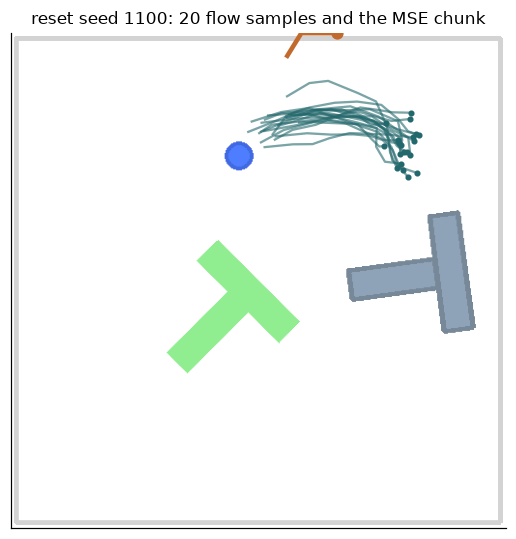

In [9]:
from pusht_ac.evaluation import make_env
env = make_env(); obs0, _ = env.reset(seed=1100); env.close()
s0 = torch.as_tensor(normalizer.normalize_state(obs0), dtype=torch.float32)[None]
g = torch.Generator().manual_seed(11)
with torch.no_grad():
    samp0 = np.clip(np.stack([normalizer.denormalize_action(flow.sample_actions(s0, generator=g)[0].numpy()) for _ in range(20)]), 0, 512)
    m0 = np.clip(normalizer.denormalize_action(mse(s0)[0].numpy()), 0, 512)
fig, ax = plt.subplots(figsize=(5, 5))
viz.show_scene(ax, obs0, title='reset seed 1100: 20 flow samples and the MSE chunk')
for smp in samp0:
    ax.plot(*smp.T, '-', color=PAL['flow'], alpha=0.6); ax.plot(*smp[-1], 'o', color=PAL['flow'], ms=3)
ax.plot(*m0.T, '-', color=PAL['mse'], lw=3); ax.plot(*m0[-1], 'o', color=PAL['mse'], ms=7)
plt.tight_layout(); plt.savefig(RES / 'flow_samples_seed1100.png', bbox_inches='tight'); plt.show()

### Representative rollouts

best     reset seed 1002: score 1.000, success True, length 281


worst    reset seed 1094: score 0.000, success False, length 300


seed1100 reset seed 1100: score 0.977, success False, length 300


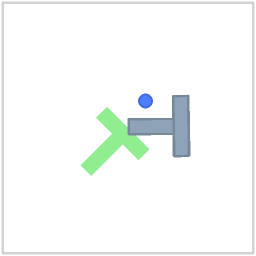

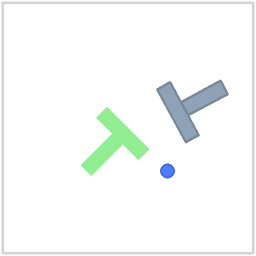

In [10]:
order = flow_df.sort_values(['success', 'max_reward'], ascending=False)
picks = {'best': int(order.reset_seed.iloc[0]), 'worst': int(order.reset_seed.iloc[-1]), 'seed1100': 1100}
for name, seed in picks.items():
    e = rollout(flow, normalizer, seed, seed, render=True)
    save_gif(e.frames, RES / f'flow_{name}.gif')
    print(f'{name:8s} reset seed {seed}: score {e.max_reward:.3f}, success {e.success}, length {e.length}')
json.dump(picks, open(RES / 'gif_seeds.json', 'w'))
display(ShowImage(filename=str(RES / 'flow_best.gif')), ShowImage(filename=str(RES / 'flow_worst.gif')))

## 5. Findings (Part 2)

**Construction check.** All seven checks pass: $A_0=\epsilon$, $A_1=A$, $A_{0.25}=0.75\epsilon+0.25A$, the target
$u=A-\epsilon$ has shape `[B, 8, 2]`, the network input has 22 values, and the output is `[B, 8, 2]`. At sampling
time the network only ever sees $(o, Z_n, n/N)$.

**Training.** Same MLP (3 × 256), optimizer, batch size, 150k steps and checkpoint rule as Part 1. Training took
194 s against 272 s for MSE. Both are single-process CPU wall-clock times and are sensitive to background load; the
per-step cost is essentially the same. The flow validation loss bottoms out at 0.235 (step ~73k) and ends at 0.259,
while the validation rollout score peaks at 0.888 at step 130k, the chosen checkpoint. The raw values (~0.24 for flow,
~0.10 for MSE) are not comparable. The flow target $A-\epsilon$ contains the fresh noise, so even a perfect velocity
field has a large irreducible error, and the two losses measure different quantities.

**Test comparison** (same 100 reset seeds, policy-noise seed = reset seed):

| | MSE (Part 1) | Flow, N = 10 (Part 2) |
|---|---|---|
| score $R_e$, mean ± std | 0.575 ± 0.397 | **0.840 ± 0.265** |
| median score | 0.74 | 0.96 |
| success rate | 11% | **22%** |
| episodes with $R_e<0.1$ | 22 | 4 |
| ms per policy query | 0.13 | 0.60 |
| rollout time, 100 episodes | 7.2 s | 8.8 s |

On the same seeds, flow − MSE = **+0.265** (bootstrap 95% CI 0.174 to 0.356, sign-flip p < 1e-4). Flow is better
on 70 seeds, worse on 25 and tied on 5. Two more passes with new policy-noise seeds give 0.837 (20% success) and
0.870 (27%). The advantage is far larger than the noise from sampling alone.

**Runtime.** A flow query costs 10 network evaluations instead of 1 (≈ 4.6× the policy time). The physics and the
Python loop still dominate the episode cost, so a full rollout is only ~20% slower.

**Integration steps.** On validation seeds the score rises from 0.62 at $N=1$ to 0.74 at $N=2$ and 0.87 at $N=4$,
then plateaus (0.89 at $N=10$, 0.85 at $N=20$, 0.84 at $N=50$). The $N=10$ value is optimistic, because the checkpoint
was chosen at $N=10$ on these same seeds. A single Euler step from $\tau=0$ ideally returns exactly the conditional
mean, since $v^*(o,z,0)=\mathbb E[A\mid o]-z$ gives $Z_1=\mathbb E[A\mid o]$. Fittingly, the $N=1$ score (0.62)
lands in the range of the MSE policy (0.68 validation).

**Sampled chunks.** At the ambiguous observation from Part 1, 30 samples spread over the region the neighbouring
experts used (endpoint std ≈ 27 / 23 px), with most samples sweeping right along the T and a few heading up-left like
the other expert group. The MSE chunk is a single path. At the start of seed 1100 the flow samples agree on heading
toward the T, while the MSE chunk leaves the arena (this is the start of the MSE wall-pinning failure). Variability
is not automatically useful: some samples in the left panel cut across the T's bar. The rollouts are what show that
the distribution helps.

**Failures.** The worst flow episode (seed 1094, score 0) circles a corner of the T near the upper-right without a
decisive push. That is the same "hovering" failure as MSE, but much rarer (4 vs. 22 episodes below 0.1). Most flow
non-successes are near misses: 70 episodes reach ≥ 0.9 but only 22 cross the 95%-coverage threshold, and the policy
often keeps adjusting the T around 0.9–0.95 coverage until the time limit (seed 1100: 0.977, no success).

The Part 2 checkpoint (`checkpoints/flow_policy.pt`, SHA-256 in `results_part2/flow_checkpoint_sha256.txt`) is
saved unchanged for Part 3.